<div class="alert alert-success">

## Instructions to students

If the assignment was fetched from the assignments tab, do not change the name of the assignment file(s).

### Code answers

In questions that require you to write code, there will be a code cell containing: 
    
<code># YOUR CODE HERE</code>
<br>
<code>raise NotImplementedError()</code>
    
When you are ready to write your answer, delete <code>raise NotImplementedError()</code> and write your code.

### Submitting your work
    
You should save your work before you submit ("Save" icon in top menu).
    
Before you submit, ensure that the notebook can be run from start to finish by pressing the "Restart & Run All" option in the "Kernel" menu above.
    
Once you are ready, go to the assignments tab on the Noteable landing page and click "Submit" on the relevant assignment.

</div>

### Question 2:
 The code in the cell below has errors. These errors prevent the code from running as intended. 

Your **task** is to find all the mistakes and fix them so that the code functions properly and presents a correct figure at the end. 

It is strongly recommended to start the exercise by copying the entire code to a separate python file and examine it in Spyder/VS Code etc. 

**Note A**: Leave the function names unchanged. Some may be assumed in tests. Constant values as given are all correct.

**Note B**: Copy your final solution back into the cell below so that the tests can run.

##### What is this code?

The fault-finding exercises permit bringing detailed, relevant code and algorithms to your attention. This exercise uses an unseen algorithm, a classic Newton-Raphson root finder method.

The purpose of this exercise is to understand how `SciPy.optimize.curvefit()` works behind the scenes, albeit in a simple way. The SciPy code is far more sophisticated (and robust) than we will implement here. 

Nevertheless, this exercise shows fitting with the least squares method. The model function is the `my_func()` function, and the root finder seeks the extremum (zero of the first derivative) of the least squares formula for data with equal weights (all set to 1). 

The least squares target function to minimize for fitting is $$\chi^{2}(g(x_{i};a_{m}))=\sum_{i=1}^{N_{D}}\,\left(\frac{y_{i}-g(x_{i};a_{m})}{\sigma_{i}}\right)^{2}.$$ 

The $\sigma_{i}$ values are the weights (all set to 1 hence they don't show up below). The sum runs over $N_{D}$ data items, with $y_{i}$ the measured data values and $g(x_{i};a_{m})$ the model function, depending on the independent variable values $x_{i}$ and the $m$ free parameters $a_{m}$. Below we use only a single(!) free parameter, the frequency of our artificial data.

We need its first-derivative and a root finder method to find the zero. You can find plenty of literature on the Newton-Raphson method. Here, we use the central difference approximation to differentiation (can only be discrete on a computer) using $$\frac{df}{dx}|_{CD}=\frac{f(x+\delta{}x/2)-f(x-\delta{}x/2)}{\delta{}x},$$ where $\delta{}x$ is a small but finite step value.

The Newton-Raphson method iterates over potential root values until it converges close enough to a zero to stop the search. Note that the method depends heavily on the starting value for its search.

The code below, once repaired, should show the fitting (root finding) fail for some initial values of the frequency (see the loop), and show successful fits for initial values close enough to the actual true value of the frequency. 

Note however, due to randomness, the exact behaviour can vary and you may see all fits "technically succeeding". You should try running a few times to see general behaviour. The tests are not affected by this randomness.

The fit that converges fastest (fewest number of iterations) is then taken to make the plot, showing the data and the best fit curve.

Initial guess x0 = 3.8
  Root found: root = 4.496818623241548, f(root) = -3.6936564917766646e-12, iterations = 4
Initial guess x0 = 3.9
  Root found: root = 4.496818623241465, f(root) = -3.314182261959786e-11, iterations = 4
Initial guess x0 = 4.0
  Root found: root = 4.496818623241478, f(root) = -2.8442248556359573e-11, iterations = 4
Initial guess x0 = 4.1
  Root found: root = 4.496818623241542, f(root) = -5.883404874396092e-12, iterations = 4
Initial guess x0 = 4.2
  Root found: root = 4.496818623241558, f(root) = -2.473021787352536e-13, iterations = 4
Initial guess x0 = 4.3
  Root found: root = 4.496818623241559, f(root) = 6.539213615042172e-14, iterations = 4
Initial guess x0 = 4.4
  Root found: root = 4.496818623241559, f(root) = 6.539213615042172e-14, iterations = 4
Initial guess x0 = 4.5
  Root found: root = 4.496818623241559, f(root) = 6.539213615042172e-14, iterations = 3
Initial guess x0 = 4.6
  Root found: root = 4.496818623241559, f(root) = 6.539213615042172e-14, iteration

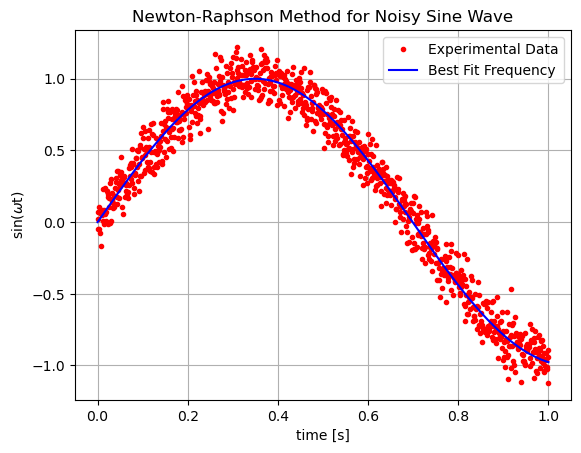

In [20]:
# YOUR CODE HERE

'''
Script:
Demonstrate elementary curve fitting.
This example contains faults.
The plot should show the slightly noisy my_func() curve in red 
for 4.5 Hz for a second and a best fit curve in blue.
'''

import numpy as np
import matplotlib.pyplot as plt

def my_func(t, freq):
    ''' Model function, unit amplitude.'''
    return np.sin(freq * t)

def Newton_Raphson(func, x0, dx, args, eps=1.e-9, Nmax=10):
    ''' Newton-Raphson root finder function. Default precision and maximum number of iterations.'''
    ff = args[0]
    ts = args[1]
    da = args[2]
    print(f"Initial guess x0 = {x0}")
    for it in range(Nmax + 1):
        F = func(ff, ts, da, x0) ## ERROR - NEEDED FOURTH ARGUMENT x0
        if ( abs (F) <= eps ): # Converged?
            print (f"  Root found: root = {x0}, f(root) = {F}, iterations = {it}")
            return x0, it #ERROR - NO EXIT FROM THIS LOOP of ITERATIONS
        df = (func(ff, ts, da, x0+dx/2) - func(ff, ts, da, x0-dx/2))/dx # Central difference '''ERROR HAD + instead of - AND DIV BY x0 not dx'''
 
        x0 += -F / df # New guess
        
    if it >= Nmax:
        print (f"   Newton Failed for Nmax = {Nmax}")
        return x0, it ##ERROR - indentation, need return to be indented in line iwth print

def derivative(model, x, data, par):
    ''' Objective function to solve for fitting.'''
    return np.sum((data-model(x,par))*-2*x*np.cos(par*x))## ERROR - used + instead of - for data-model AND Derivative should be -2t*cos(par*t)


##################################################
# Create some data - DO NOT CHANGE DATA GENERATION
par   = 4.5 # [Hz] 
times = np.linspace(0,1,1000) # [s] 
data  = my_func(times, par) # noise-free data first, at set frequency
data += np.random.normal(scale=0.1,size=len(data)) # small amount of noise added
##################################################

# Find the root of the first derivative of the least_square function - extremum
step = 1.e-4 # DO NOT CHANGE
roots = []
n_its  = []
for val in range(-7,7): # DO NOT CHANGE
    p0 = par+0.1*val # DO NOT CHANGE
    root, n_it = Newton_Raphson(derivative, p0, step, args=(my_func, times, data))
    roots.append(root)
    n_its.append(n_it)
root = roots[np.argmin(n_its)] # Use fit with lowest iterations for best fitted par value, important for test.

print(f"============================")
print(f"Best fit root = {root}")
print(f"============================")
# Plot data and best fit curve
plt.plot(times, data,'r.', label="Experimental Data")  #ADDED LABELS
plt.grid()
plt.plot(times, my_func(times, root), 'b', label="Best Fit Frequency")
plt.xlabel('time [s]')
plt.ylabel(r'sin($\omega$t)')
plt.title("Newton-Raphson Method for Noisy Sine Wave") #ADDED TITLE
plt.legend() #ADDED LEGEND
plt.show()

Marks cell - do not delete

In [ ]:
# test, do not delete

### Tests - 1 mark; Plot - 2 marks